In [16]:
import csv
import random

def generate_flight(filename="flight_log.csv"):
    # Fija semilla opcional para reproducibilidad
    random.seed(42)

    dt = 0.1          # Paso de tiempo: 100 ms (10 Hz)
    g = 9.81          # Gravedad (m/s^2)
    T0 = 20.0         # Temperatura inicial en rampa (°C)
    lapse_rate = 0.0065  # Gradiente térmico estándar (°C/m)

    # Variables de estado inicial
    t = 0.0
    h = 0.0
    v = 0.0
    rows = []

    def record_sample(time_s, alt_true, accel_net):
        # 1. Ruido gaussiano en barómetro (sigma = 0.5 m)
        alt_noisy = alt_true + random.gauss(0.0, 0.5)

        # 2. Lectura real del acelerómetro (fuerza específica + pequeño ruido de sensor)
        accel_sensor = (accel_net + g) + random.gauss(0.0, 0.05)

        # 3. Temperatura según altitud real (+ pequeño ruido de termistor)
        temp_c = (T0 - lapse_rate * max(0.0, alt_true)) + random.gauss(0.0, 0.05)

        rows.append([
            int(round(time_s * 1000)),
            round(alt_noisy, 3),
            round(accel_sensor, 3),
            round(temp_c, 2)
        ])

    # --- FASE 1: En rampa (2.0 s) ---
    steps_ramp = int(2.0 / dt)
    for _ in range(steps_ramp):
        record_sample(t, h, 0.0)
        t += dt

    # --- FASE 2: Propulsión (1.5 s, aceleración neta = +60 m/s^2) ---
    steps_boost = int(1.5 / dt)
    a_boost = 60.0
    for _ in range(steps_boost):
        record_sample(t, h, a_boost)
        h += v * dt + 0.5 * a_boost * (dt ** 2)
        v += a_boost * dt
        t += dt

    # --- FASE 3: Vuelo balístico (solo gravedad hasta el apogeo, v <= 0) ---
    a_coast = -g
    while v > 0:
        record_sample(t, h, a_coast)
        h += v * dt + 0.5 * a_coast * (dt ** 2)
        v += a_coast * dt
        t += dt

    print(f"Apogeo real simulado: {h:.2f} m en t = {t:.1f} s")

    # --- FASE 4: Paracaídas (descenso a velocidad casi constante ~ -6 m/s) ---
    v = -6.0
    while h > 0:
        record_sample(t, h, 0.0)
        h += v * dt
        if h < 0:
            h = 0.0
        t += dt

    # --- FASE 5: En tierra (3.0 s) ---
    steps_landed = int(3.0 / dt)
    for _ in range(steps_landed):
        record_sample(t, 0.0, 0.0)
        t += dt

    # --- INSERCIÓN DE 3 LÍNEAS CORRUPTAS (paquetes perdidos) ---
    # 1. Campo vacío en altitud
    rows[25] = [rows[25][0], "", rows[25][2], rows[25][3]]
    # 2. Texto 'ERR' en aceleración
    rows[60] = [rows[60][0], rows[60][1], "ERR", rows[60][3]]
    # 3. Columna faltante (solo 3 columnas en vez de 4)
    rows[110] = [rows[110][0], rows[110][1], rows[110][2]]

    # Escribir archivo CSV
    with open(filename, mode="w", newline="", encoding="utf-8") as f:
        writer = csv.writer(f)
        writer.writerow(["time_ms", "altitude_m", "accel_z_ms2", "temp_c"])
        writer.writerows(rows)

    print(f"Archivo '{filename}' generado con {len(rows)} registros (incluyendo 3 corruptos).")

if __name__ == "__main__":
    generate_flight()

Apogeo real simulado: 480.34 m en t = 12.7 s
Archivo 'flight_log.csv' generado con 958 registros (incluyendo 3 corruptos).


=== RESUMEN DE TELEMETRÍA (ESTACIÓN TERRENA) ===
Líneas corruptas descartadas : 3
  - Línea 27: valor inválido o faltante -> ['2500', '', '69.858', '19.92']
  - Línea 62: valor inválido o faltante -> ['6000', '261.746', 'ERR', '18.32']
  - Línea 112: se esperaban 4 columnas, llegaron 3 -> ['11000', '466.74', '-0.037']
Detección de eventos           : despegue=2.00s | apogeo=12.70s | aterrizaje=93.30s
Apogeo                         : 479.96 m en t = 12.70 s
Velocidad máxima de ascenso     : 89.25 m/s en t = 3.80 s
Velocidad promedio de descenso : -5.95 m/s
Tiempo total de vuelo          : 91.30 s (registro total: 95.70 s)
Archivo generado               : /content/flight_processed.csv


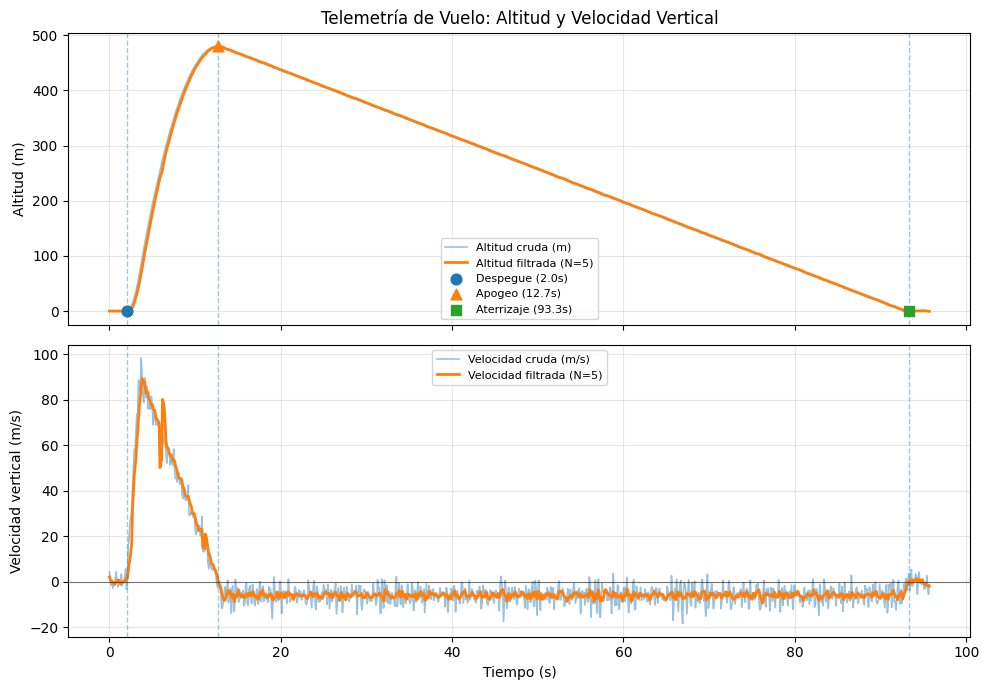

In [17]:
from __future__ import annotations

import csv
import math
from pathlib import Path
from typing import Any

import matplotlib.pyplot as plt


def parse_number(raw: str | None, as_int: bool = False) -> float | int | None:
    """Convierte a int o float de forma segura; devuelve None si es vacío, texto o no finito."""
    if raw is None:
        return None
    text = raw.strip()
    if not text:
        return None
    try:
        val = float(text)
    except ValueError:
        return None
    if math.isnan(val) or math.isinf(val):
        return None
    return int(round(val)) if as_int else val


def load_flight_log(csv_path: Path) -> tuple[list[dict[str, Any]], int, list[str]]:
    """
    Lee flight_log.csv línea por línea, descarta filas corruptas sin detenerse
    y devuelve (registros_validos, total_descartadas, detalle_descartes).
    """
    if not csv_path.exists():
        raise FileNotFoundError(f"No se encontró el archivo '{csv_path}'.")

    expected_headers = ["time_ms", "altitude_m", "accel_z_ms2", "temp_c"]
    records: list[dict[str, Any]] = []
    discarded_details: list[str] = []

    with csv_path.open(mode="r", encoding="utf-8", newline="") as f:
        reader = csv.reader(f)
        headers = next(reader, None)
        if headers != expected_headers:
            raise ValueError(
                f"Encabezados inesperados: {headers}. Se esperaban: {expected_headers}"
            )

        for line_num, row in enumerate(reader, start=2):
            if len(row) != 4:
                discarded_details.append(
                    f"Línea {line_num}: se esperaban 4 columnas, llegaron {len(row)} -> {row}"
                )
                continue

            time_ms = parse_number(row[0], as_int=True)
            alt_m = parse_number(row[1], as_int=False)
            accel_ms2 = parse_number(row[2], as_int=False)
            temp_c = parse_number(row[3], as_int=False)

            if None in (time_ms, alt_m, accel_ms2, temp_c):
                discarded_details.append(
                    f"Línea {line_num}: valor inválido o faltante -> {row}"
                )
                continue

            records.append(
                {
                    "time_ms": int(time_ms),
                    "time_s": float(time_ms) / 1000.0,
                    "alt_raw": float(alt_m),
                    "accel_z_ms2": float(accel_ms2),
                    "temp_c": float(temp_c),
                }
            )

    records.sort(key=lambda r: r["time_ms"])
    return records, len(discarded_details), discarded_details


def moving_average_backward(values: list[float], window_n: int) -> list[float]:
    """
    Promedio móvil de ventana N:
    h_bar_i = (1 / N) * sum_{k=0}^{N-1} h_{i-k}
    Para los primeros índices (i + 1 < N), usa las muestras disponibles hasta i.
    """
    if window_n < 1:
        raise ValueError("La ventana N del promedio móvil debe ser >= 1.")
    if not values:
        return []

    filtered: list[float] = []
    for i in range(len(values)):
        start_idx = max(0, i - window_n + 1)
        window_slice = values[start_idx : i + 1]
        filtered.append(sum(window_slice) / len(window_slice))
    return filtered


def finite_diff_velocity(times_s: list[float], altitudes_m: list[float]) -> list[float]:
    """
    Calcula velocidad vertical por diferencias finitas:
    - Interior: v_i = (h_{i+1} - h_{i-1}) / (t_{i+1} - t_{i-1})
    - Extremos: diferencia hacia adelante / hacia atrás
    """
    n = len(altitudes_m)
    if n == 0:
        return []
    if n == 1:
        return [0.0]

    vels: list[float] = []
    for i in range(n):
        if i == 0:
            dt = times_s[1] - times_s[0]
            vels.append((altitudes_m[1] - altitudes_m[0]) / dt if dt != 0 else 0.0)
        elif i == n - 1:
            dt = times_s[-1] - times_s[-2]
            vels.append((altitudes_m[-1] - altitudes_m[-2]) / dt if dt != 0 else 0.0)
        else:
            dt = times_s[i + 1] - times_s[i - 1]
            vels.append((altitudes_m[i + 1] - altitudes_m[i - 1]) / dt if dt != 0 else 0.0)
    return vels


def detect_events(
    times_s: list[float],
    alt_filt: list[float],
    vel_filt: list[float],
    accels: list[float],
    liftoff_acc_threshold: float = 20.0,
    liftoff_vel_threshold: float = 2.0,
    consecutive_needed: int = 3,
    landed_alt_threshold: float = 0.8,
    landed_vel_threshold: float = 0.8,
) -> dict[str, Any]:
    """
    Detecta despegue, apogeo y aterrizaje a partir de señales físicas y filtradas.
    """
    n = len(times_s)
    liftoff_idx = 0

    # 1. Despegue: primeras `consecutive_needed` muestras consecutivas con aceleración
    # de sensor > umbral o velocidad ascendente clara tras rampa.
    streak = 0
    for i in range(n):
        if accels[i] > liftoff_acc_threshold or (i > 15 and vel_filt[i] > liftoff_vel_threshold):
            streak += 1
            if streak >= consecutive_needed:
                liftoff_idx = i - consecutive_needed + 1
                break
        else:
            streak = 0

    # 2. Apogeo: máximo de altitud filtrada a partir del despegue
    apogee_idx = liftoff_idx
    for i in range(liftoff_idx, n):
        if alt_filt[i] > alt_filt[apogee_idx]:
            apogee_idx = i

    # 3. Aterrizaje: tras el apogeo, primeras `consecutive_needed` muestras consecutivas
    # con altitud filtrada baja y velocidad vertical cercana a cero.
    landed_idx = n - 1
    streak = 0
    for i in range(apogee_idx + 1, n):
        if abs(alt_filt[i]) <= landed_alt_threshold and abs(vel_filt[i]) <= landed_vel_threshold:
            streak += 1
            if streak >= consecutive_needed:
                landed_idx = i - consecutive_needed + 1
                break
        else:
            streak = 0

    return {
        "liftoff_idx": liftoff_idx,
        "liftoff_t": times_s[liftoff_idx],
        "liftoff_alt": alt_filt[liftoff_idx],
        "apogee_idx": apogee_idx,
        "apogee_t": times_s[apogee_idx],
        "apogee_alt": alt_filt[apogee_idx],
        "landed_idx": landed_idx,
        "landed_t": times_s[landed_idx],
        "landed_alt": alt_filt[landed_idx],
    }


def compute_summary(
    times_s: list[float],
    alt_filt: list[float],
    vel_filt: list[float],
    events: dict[str, Any],
    discarded_count: int,
) -> dict[str, Any]:
    """Calcula las métricas exigidas en el resumen de la estación terrena."""
    liftoff_idx = events["liftoff_idx"]
    apogee_idx = events["apogee_idx"]
    landed_idx = events["landed_idx"]

    max_ascent_vel = max(vel_filt) if vel_filt else 0.0
    max_ascent_idx = vel_filt.index(max_ascent_vel) if vel_filt else 0

    # Velocidad promedio de descenso (entre apogeo y aterrizaje)
    descent_slice = vel_filt[apogee_idx : landed_idx + 1] if landed_idx >= apogee_idx else []
    avg_descent_vel = (sum(descent_slice) / len(descent_slice)) if descent_slice else 0.0

    # Tiempo total de vuelo (desde despegue hasta aterrizaje) y duración total del registro
    flight_duration_s = max(0.0, events["landed_t"] - events["liftoff_t"])
    log_duration_s = max(0.0, times_s[-1] - times_s[0]) if len(times_s) >= 2 else 0.0

    return {
        "apogee_m": events["apogee_alt"],
        "apogee_t_s": events["apogee_t"],
        "max_ascent_vel_mps": max_ascent_vel,
        "max_ascent_vel_t_s": times_s[max_ascent_idx],
        "avg_descent_vel_mps": avg_descent_vel,
        "flight_duration_s": flight_duration_s,
        "log_duration_s": log_duration_s,
        "discarded_lines": discarded_count,
        "liftoff_t_s": events["liftoff_t"],
        "landed_t_s": events["landed_t"],
    }


def save_flight_processed_csv(
    output_path: Path,
    times_s: list[float],
    alt_raw: list[float],
    alt_filt: list[float],
    vel_raw: list[float],
    vel_filt: list[float],
) -> None:
    """Guarda flight_processed.csv con tiempo, altitud y velocidad (cruda y filtrada)."""
    with output_path.open(mode="w", encoding="utf-8", newline="") as f:
        writer = csv.writer(f)
        writer.writerow(
            [
                "time_s",
                "altitude_raw_m",
                "altitude_filtered_m",
                "velocity_raw_mps",
                "velocity_filtered_mps",
            ]
        )
        for t, hr, hf, vr, vf in zip(times_s, alt_raw, alt_filt, vel_raw, vel_filt):
            writer.writerow(
                [
                    round(t, 3),
                    round(hr, 4),
                    round(hf, 4),
                    round(vr, 4),
                    round(vf, 4),
                ]
            )


def plot_flight_diagnostics(
    times_s: list[float],
    alt_raw: list[float],
    alt_filt: list[float],
    vel_raw: list[float],
    vel_filt: list[float],
    events: dict[str, Any],
    window_n: int,
) -> None:
    """Genera (a) altitud vs. tiempo con eventos marcados y (b) velocidad vs. tiempo."""
    fig, (ax_alt, ax_vel) = plt.subplots(2, 1, figsize=(10, 7), sharex=True)

    # (a) Altitud vs. tiempo
    ax_alt.plot(times_s, alt_raw, label="Altitud cruda (m)", alpha=0.45, linewidth=1.2)
    ax_alt.plot(
        times_s,
        alt_filt,
        label=f"Altitud filtrada (N={window_n})",
        linewidth=2.0,
    )

    event_points = [
        ("Despegue", events["liftoff_t"], events["liftoff_alt"], "o"),
        ("Apogeo", events["apogee_t"], events["apogee_alt"], "^"),
        ("Aterrizaje", events["landed_t"], events["landed_alt"], "s"),
    ]
    for label, t_ev, h_ev, marker in event_points:
        ax_alt.scatter([t_ev], [h_ev], marker=marker, s=60, zorder=5, label=f"{label} ({t_ev:.1f}s)")
        ax_alt.axvline(t_ev, linestyle="--", alpha=0.4, linewidth=1.0)

    ax_alt.set_ylabel("Altitud (m)")
    ax_alt.set_title("Telemetría de Vuelo: Altitud y Velocidad Vertical")
    ax_alt.grid(True, alpha=0.3)
    ax_alt.legend(loc="best", fontsize=8)

    # (b) Velocidad vs. tiempo
    ax_vel.plot(times_s, vel_raw, label="Velocidad cruda (m/s)", alpha=0.45, linewidth=1.2)
    ax_vel.plot(
        times_s,
        vel_filt,
        label=f"Velocidad filtrada (N={window_n})",
        linewidth=2.0,
    )
    ax_vel.axhline(0.0, color="black", linewidth=0.8, alpha=0.5)
    for _, t_ev, _, _ in event_points:
        ax_vel.axvline(t_ev, linestyle="--", alpha=0.4, linewidth=1.0)

    ax_vel.set_xlabel("Tiempo (s)")
    ax_vel.set_ylabel("Velocidad vertical (m/s)")
    ax_vel.grid(True, alpha=0.3)
    ax_vel.legend(loc="best", fontsize=8)

    plt.tight_layout()
    plt.show()


def main() -> None:
    # Ajusta input_path a "flight_log.csv" o "sample_data/flight log.csv" según dónde esté
    input_path = Path("flight_log.csv")
    output_path = Path("flight_processed.csv")
    window_n = 5

    records, discarded_count, discarded_details = load_flight_log(input_path)
    if not records:
        raise ValueError("No hay registros válidos en el archivo de telemetría.")

    times_s = [r["time_s"] for r in records]
    alt_raw = [r["alt_raw"] for r in records]
    accels = [r["accel_z_ms2"] for r in records]

    alt_filt = moving_average_backward(alt_raw, window_n=window_n)
    vel_raw = finite_diff_velocity(times_s, alt_raw)
    vel_filt = finite_diff_velocity(times_s, alt_filt)

    events = detect_events(times_s, alt_filt, vel_filt, accels)
    summary = compute_summary(times_s, alt_filt, vel_filt, events, discarded_count)

    save_flight_processed_csv(output_path, times_s, alt_raw, alt_filt, vel_raw, vel_filt)

    print("=== RESUMEN DE TELEMETRÍA (ESTACIÓN TERRENA) ===")
    print(f"Líneas corruptas descartadas : {summary['discarded_lines']}")
    for detail in discarded_details:
        print(f"  - {detail}")
    print(f"Detección de eventos           : despegue={summary['liftoff_t_s']:.2f}s | "
          f"apogeo={summary['apogee_t_s']:.2f}s | aterrizaje={summary['landed_t_s']:.2f}s")
    print(f"Apogeo                         : {summary['apogee_m']:.2f} m en t = {summary['apogee_t_s']:.2f} s")
    print(f"Velocidad máxima de ascenso     : {summary['max_ascent_vel_mps']:.2f} m/s en t = {summary['max_ascent_vel_t_s']:.2f} s")
    print(f"Velocidad promedio de descenso : {summary['avg_descent_vel_mps']:.2f} m/s")
    print(f"Tiempo total de vuelo          : {summary['flight_duration_s']:.2f} s (registro total: {summary['log_duration_s']:.2f} s)")
    print(f"Archivo generado               : {output_path.resolve()}")

    plot_flight_diagnostics(times_s, alt_raw, alt_filt, vel_raw, vel_filt, events, window_n)


if __name__ == "__main__":
    main()

In [12]:
from pathlib import Path

print("Directorio actual:", Path.cwd())
print("CSV en /content:", list(Path("/content").rglob("*.csv")))

Directorio actual: /content
CSV en /content: [PosixPath('/content/flight_log.csv'), PosixPath('/content/sample_data/california_housing_train.csv'), PosixPath('/content/sample_data/mnist_test.csv'), PosixPath('/content/sample_data/mnist_train_small.csv'), PosixPath('/content/sample_data/california_housing_test.csv')]
